# Varianza marginal con shocks persistentes: una comparación reproducible

**Pregunta.** ¿Qué cambia al llevar la varianza de shocks AR(1) a la misma pérdida monetaria del programa de inconsistencia temporal? La comparación separa estimación, incertidumbre y decisión. Todos los datos son sintéticos; el experimento no valida parámetros macroeconómicos reales.

La hipótesis técnica de cribado se fijó antes de inspeccionar los resultados: para cada una de 8 celdas, el límite inferior Wilson 95% de la cobertura del intervalo GLS exacto debe ser ≥0.80, con 90 trayectorias por celda. Este umbral no sustituye la cobertura teórica y puede fallar por variación Monte Carlo.

## Modelo y fórmula

Sea $X_t=\mu+U_t$, $U_t=\rho U_{t-1}+\eta_t$, $|\rho|<1$, y $\eta_t\sim N(0,v(1-\rho^2))$. La varianza marginal $v$ tiene unidades de shock$^2$. El módulo previo trataba shocks independientes, donde $(n-1)s^2/v\sim\chi^2_{n-1}$. Con AR(1), esa identidad iid no aplica.

Para $D_t=X_t-X_{t-1}$, la autocovarianza es $\gamma_D(h)=-v(1-\rho)^2\rho^{h-1}$ para $h\ge1$, y $\operatorname{Var}(D_t)=2v(1-\rho)$. Así $Z_t=D_t^2/[2(1-\rho)]$ sigue siendo insesgado para $v$, pero los cuadrados de diferencias adyacentes se correlacionan.

In [1]:
import json
from pathlib import Path
import numpy as np
from src.dependent_interval import paired_chebyshev_interval, gls_chisquare_interval, iid_chisquare_interval, pair_variance_coefficient

root = Path.cwd()
config = json.loads((root / 'dependent-config.json').read_text())
print('Seeds:', config['seeds'], 'n:', config['n'], 'rho:', config['rho'], 'replicas/celda:', config['repetitions_per_seed_cell'] * len(config['seeds']))
x = np.random.default_rng(1103).normal(size=64)
for estimate in [iid_chisquare_interval(x), paired_chebyshev_interval(x, 0.0), gls_chisquare_interval(x, 0.0)]:
    print(estimate)

Seeds: [1103, 1104, 1105] n: [64, 256] rho: [0.0, 0.5, 0.9, 0.95] replicas/celda: 90
VarianceEstimate(estimate=0.9894008848481963, low=0.755279505180703, high=1.3627105270840696, confidence=0.9, observations=64, method='iid_chisquare', abstained=False)
VarianceEstimate(estimate=0.863524090944305, low=0.5114944172349056, high=2.769814454912483, confidence=0.9, observations=64, method='paired_chebyshev', abstained=False)
VarianceEstimate(estimate=0.9894008848481965, low=0.7552795051807032, high=1.3627105270840698, confidence=0.9, observations=64, method='gls_chisquare', abstained=False)


## Derivación del intervalo por pares

Para un proceso gaussiano, Isserlis implica $\operatorname{Cov}(D_t^2,D_s^2)=2\gamma_D(s-t)^2$. Con $m=n-1$ diferencias,

$$\frac{\operatorname{Var}(\hat v_P)}{v^2}=c_{m,\rho}=\frac{2m+(1-\rho)^2\sum_{h=1}^{m-1}(m-h)\rho^{2(h-1)}}{m^2}.$$

Chebyshev aplicado al error relativo da $P(|\hat v_P/v-1|\ge\epsilon)\le c/\epsilon^2$. Fijando $\epsilon=\sqrt{c/\alpha}<1$ se obtiene $[\hat v_P/(1+\epsilon),\hat v_P/(1-\epsilon)]$ con cobertura al menos $1-\alpha$. Si $\epsilon\ge1$, no hay límite superior finito y la implementación se abstiene. Esto requiere $\rho$ conocido y gaussianidad conjunta; no se extrapola a parámetros estimados o cambios de régimen.

In [2]:
n = 64
rho = 0.0
coefficient = pair_variance_coefficient(n, rho)
epsilon = (coefficient / (1 - config['confidence'])) ** 0.5
paired = paired_chebyshev_interval(x, rho)
print({'relative_variance_coefficient': coefficient, 'chebyshev_radius': epsilon, 'paired_interval': paired})
assert abs(coefficient - (3*(n-1)-1)/(n-1)**2) < 1e-14
assert paired.low is not None and paired.high is not None and paired.low <= paired.estimate <= paired.high

{'relative_variance_coefficient': 0.047367094986142604, 'chebyshev_radius': 0.6882375678945651, 'paired_interval': VarianceEstimate(estimate=0.863524090944305, low=0.5114944172349056, high=2.769814454912483, confidence=0.9, observations=64, method='paired_chebyshev', abstained=False)}


## Baseline, medición y resultado negativo

El baseline principal es GLS con $\rho$ conocido: blanquear los niveles AR(1) produce errores iid normales, estimar $\mu$ por GLS y obtener $RSS/v\sim\chi^2_{n-1}$. Es computacionalmente comparable $O(n)$ y estadísticamente más informativo que el intervalo Chebyshev. Se incluye la inversión iid sólo como ablación que viola dependencia. La figura muestra cobertura y bandas Wilson 95% Monte Carlo; no confundir esas bandas con un intervalo para $v$.

In [3]:
summary = json.loads((root / 'results/dependent-summary.json').read_text())
import csv
rows = list(csv.DictReader((root / 'results/dependent-aggregate.csv').open()))
for row in rows:
    if row['method'] == 'gls_chisquare':
        print('GLS', 'n='+row['n'], 'rho='+row['rho'], 'coverage='+row['coverage'], 'Wilson95=['+row['coverage_wilson_low']+', '+row['coverage_wilson_high']+']')
print('H1 passes:', summary['h1_screen_pass'], 'failures:', summary['threshold_failures_for_gls_h1'])
assert len(rows) == 24
assert summary['samples'] == 720 and summary['estimator_rows'] == 2160
assert summary['h1_screen_pass'] is False

GLS n=64 rho=0.0 coverage=0.8777777777777778 Wilson95=[0.7942625758951103, 0.9303638403451762]
GLS n=64 rho=0.5 coverage=0.9 Wilson95=[0.8207582512456635, 0.9464932483028752]
GLS n=64 rho=0.9 coverage=0.9333333333333333 Wilson95=[0.8620990522567448, 0.9690900722541721]
GLS n=64 rho=0.95 coverage=0.9222222222222223 Wilson95=[0.8480613981740798, 0.9618151846827111]
GLS n=256 rho=0.0 coverage=0.9 Wilson95=[0.8207582512456635, 0.9464932483028752]
GLS n=256 rho=0.5 coverage=0.9444444444444444 Wilson95=[0.8764626377820048, 0.976039028383038]
GLS n=256 rho=0.9 coverage=0.8666666666666667 Wilson95=[0.7812606949930235, 0.9220531795931369]
GLS n=256 rho=0.95 coverage=0.9333333333333333 Wilson95=[0.8620990522567448, 0.9690900722541721]
H1 passes: False failures: [{'n': 64, 'rho': 0.0, 'method': 'gls_chisquare', 'trials': 90, 'coverage': 0.8777777777777778, 'coverage_wilson_low': 0.7942625758951103, 'coverage_wilson_high': 0.9303638403451762, 'mean_estimate': 1.0302778730563742, 'mean_absolute_err

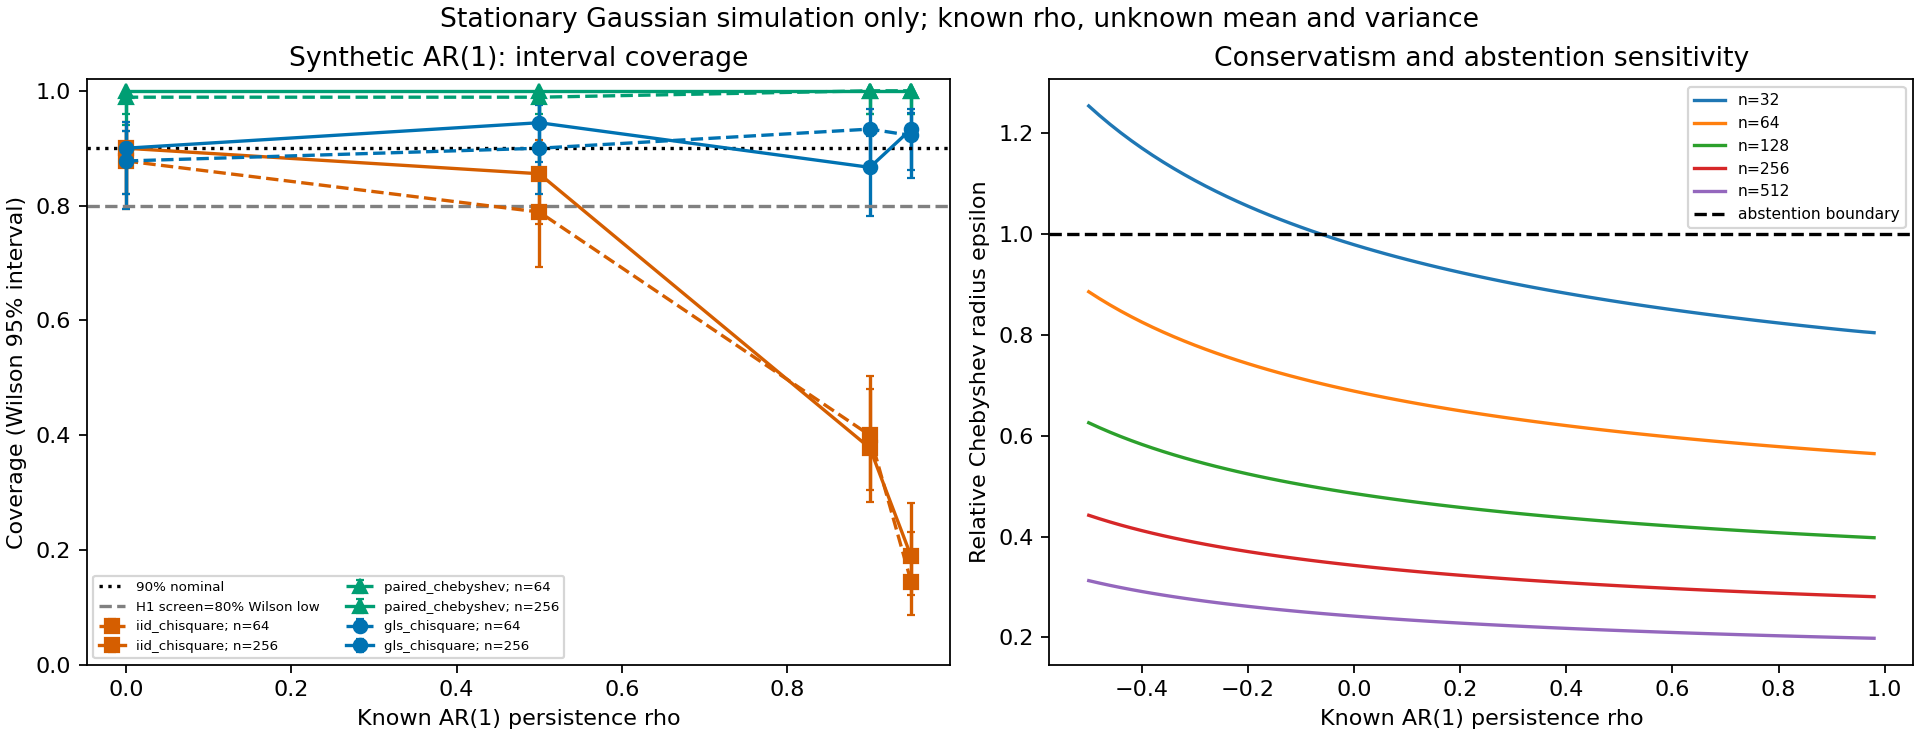

In [4]:
from IPython.display import Image, display
display(Image(filename=str(root / 'results/dependent-interval.png')))

## Lectura y límites

El umbral Wilson preespecificado falla en dos celdas GLS, aunque el pivote chi-cuadrado sea exacto bajo el modelo: son sólo 90 réplicas por celda y el cribado pide un límite inferior Monte Carlo superior a 0.80. No se cambian semillas ni umbral para borrar ese negativo. La banda inferior mínima del método por pares es más alta, pero sus intervalos son más anchos; cobertura sola no implica mejor herramienta. El GLS es la referencia competitiva porque usa correctamente toda la estructura de dependencia y es exacto bajo los mismos supuestos.

No hay evidencia empírica, identificación del shock monetario, robustez a $ho$ estimado o validez ante no normalidad/no estacionariedad. El resultado es una extensión reproducible y una refutación del filtro de cribado H1 en esta corrida, no una refutación matemática de GLS ni una contribución mundial.